# Plot the output from the analysis of the virtual balloon timeseries

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy.stats import chi2
from scipy import interpolate
import scipy.signal 
warnings.simplefilter("ignore")

### Load in the data

In [2]:
#container = np.load('GaussEnv_ThHpiover6_1000B_20P_8omega0.npz')
container = np.load('GaussEnv_RandThH_1000B_20P_8omega0.npz')
data = [container[key] for key in container]

# Constants, axes
rho_bar   = data[0]
Nref      = data[1]
f         = data[2]
frequency = data[3]
      
# Properties of the input wave packets/timeseries 
total_flux_packets   = data[4] # (n_packet_frequencies, n_balloons)
total_energy_packets = data[5] # (n_packet_frequencies, n_balloons)
Ekh_packets          = data[6] # (n_packet_frequencies, n_balloons)
Ekv_packets          = data[7] # (n_packet_frequencies, n_balloons)
Ep_packets           = data[8] # (n_packet_frequencies, n_balloons)

# Outputs: analyzed totals
Etotal_scaled_total            = data[9]  # (n_balloons)
flux_total_eachpacket          = data[10] # (n_balloons, n_packet_frequencies+1)
flux_total_upw                 = data[11] # (n_balloons)
flux_total_upw_eachpacket      = data[12] # (n_balloons)
flux_total_upw_correct_dtheta  = data[13] # (n_balloons)
flux_total_upw_correct_UpW     = data[14] # (n_balloons)
flux_total_uppt                = data[15] # (n_balloons)
flux_total_uppt_eachpacket     = data[16] # (n_balloons)
flux_total_uppt_correct_dtheta = data[17] # (n_balloons)
flux_total_uppt_correct_UpPT   = data[18] # (n_balloons)
flux_total_absupw              = data[19] # (n_balloons)
flux_total_absuppt             = data[20] # (n_balloons)
Etotal_total                   = data[21] # (n_balloons, n_packet_frequencies+1)
Ekh_total                      = data[22] # (n_balloons, n_packet_frequencies+1)
Ekv_total                      = data[23] # (n_balloons, n_packet_frequencies+1)
Ep_total                       = data[24] # (n_balloons, n_packet_frequencies+1)
up_power_total                 = data[25] # (n_balloons, n_packet_frequencies+1)

# Outputs: analyzed spectra
flux_spectrum_eachpacket          = data[26] # (nscales, n_balloons, n_packet_frequencies+1)
Etotal_scaled_spectrum            = data[27] # (nscales, n_balloons)
flux_spectrum_upw                 = data[28] # (nscales, n_balloons)
flux_spectrum_upw_eachpacket      = data[29] # (nscales, n_balloons)
flux_spectrum_uppt                = data[30] # (nscales, n_balloons)
flux_spectrum_absupw              = data[31] # (nscales, n_balloons)
flux_spectrum_absuppt             = data[32] # (nscales, n_balloons)
flux_spectrum_upw_correct_dtheta  = data[33] # (nscales, n_balloons)
flux_spectrum_upw_correct_UpW     = data[34] # (nscales, n_balloons)
flux_spectrum_upw_eachpacket      = data[35] # (nscales, n_balloons)
flux_spectrum_uppt_correct_dtheta = data[36] # (nscales, n_balloons)
flux_spectrum_uppt_correct_UpPT   = data[37] # (nscales, n_balloons)
flux_spectrum_uppt_eachpacket     = data[38] # (nscales, n_balloons)
Ekh_spectrum                      = data[39] # (nscales, n_balloons, n_packet_frequencies+1)
Ekv_spectrum                      = data[40] # (nscales, n_balloons, n_packet_frequencies+1)
Ep_spectrum                       = data[41] # (nscales, n_balloons, n_packet_frequencies+1)
up_power_spectrum                 = data[42] # (nscales, n_balloons, n_packet_frequencies+1)

nscales = flux_spectrum_eachpacket.shape[0]
n_balloons = flux_spectrum_eachpacket.shape[1]
n_packet_frequencies = flux_spectrum_eachpacket.shape[2] - 1

In [2]:
#container = np.load('GaussEnv_ThHpiover6_1000B_20P_8omega0_Boussinesq.npz')
container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq.npz')
#container = np.load('GaussEnv_RandThH_1000B_3P_8omega0_Boussinesq.npz')
data = [container[key] for key in container]

# Constants, axes
rho_bar   = data[0]
Nref      = data[1]
f         = data[2]
frequency = data[3]
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98
      
# Properties of the input wave packets/timeseries 
total_flux_packets   = data[4] # (n_packet_frequencies, n_balloons)
total_energy_packets = data[5] # (n_packet_frequencies, n_balloons)
Ekh_packets          = data[6] # (n_packet_frequencies, n_balloons)
Ekv_packets          = data[7] # (n_packet_frequencies, n_balloons)
Ep_packets           = data[8] # (n_packet_frequencies, n_balloons)

# Outputs: analyzed totals
Etotal_scaled_total            = data[9]  # (n_balloons)
flux_total_eachpacket          = data[10] # (n_balloons, n_packet_frequencies+1)
flux_total_upw                 = data[11] # (n_balloons)
flux_total_upw_eachpacket      = data[12] # (n_balloons)
flux_total_absupw_eachpacket   = data[13] # (n_balloons)
flux_total_upw_correct_dtheta  = data[14] # (n_balloons)
flux_total_upw_correct_UpW     = data[15] # (n_balloons)
flux_total_uppt                = data[16] # (n_balloons)
flux_total_uppt_eachpacket     = data[17] # (n_balloons)
flux_total_absuppt_eachpacket  = data[18] # (n_balloons)
flux_total_uppt_correct_dtheta = data[19] # (n_balloons)
flux_total_uppt_correct_UpPT   = data[20] # (n_balloons)
flux_total_absupw              = data[21] # (n_balloons)
flux_total_absuppt             = data[22] # (n_balloons)
Etotal_total                   = data[23] # (n_balloons, n_packet_frequencies+1)
Ekh_total                      = data[24] # (n_balloons, n_packet_frequencies+1)
Ekv_total                      = data[25] # (n_balloons, n_packet_frequencies+1)
Ep_total                       = data[26] # (n_balloons, n_packet_frequencies+1)
up_power_total                 = data[27] # (n_balloons, n_packet_frequencies+1)

# Outputs: analyzed spectra
flux_spectrum_eachpacket          = data[28] # (nscales, n_balloons, n_packet_frequencies+1)
Etotal_scaled_spectrum            = data[29] # (nscales, n_balloons)
flux_spectrum_upw                 = data[30] # (nscales, n_balloons)
flux_spectrum_uppt                = data[31] # (nscales, n_balloons)
flux_spectrum_absupw              = data[32] # (nscales, n_balloons)
flux_spectrum_absuppt             = data[33] # (nscales, n_balloons)
flux_spectrum_upw_correct_dtheta  = data[34] # (nscales, n_balloons)
flux_spectrum_upw_correct_UpW     = data[35] # (nscales, n_balloons)
flux_spectrum_upw_eachpacket      = data[36] # (nscales, n_balloons)
flux_spectrum_absupw_eachpacket   = data[37] # (nscales, n_balloons)
flux_spectrum_uppt_correct_dtheta = data[38] # (nscales, n_balloons)
flux_spectrum_uppt_correct_UpPT   = data[39] # (nscales, n_balloons)
flux_spectrum_uppt_eachpacket     = data[40] # (nscales, n_balloons)
flux_spectrum_absuppt_eachpacket  = data[41] # (nscales, n_balloons)
Ekh_spectrum                      = data[42] # (nscales, n_balloons, n_packet_frequencies+1)
Ekv_spectrum                      = data[43] # (nscales, n_balloons, n_packet_frequencies+1)
Ep_spectrum                       = data[44] # (nscales, n_balloons, n_packet_frequencies+1)
up_power_spectrum                 = data[45] # (nscales, n_balloons, n_packet_frequencies+1)

nscales = flux_spectrum_eachpacket.shape[0]
n_balloons = flux_spectrum_eachpacket.shape[1]
n_packet_frequencies = flux_spectrum_eachpacket.shape[2] - 1

In [36]:
# Calculate fluxes with a minimum period of 10 minutes, to be consistent with
# the superpressure balloon data

GW_PERIOD_MIN = 10 # (minutes)
#GW_PERIOD_MIN = 2*np.pi/(60*Nref)
GW_PERIOD_MAX = 2*np.pi/(60*np.abs(f))

temp1 = flux_spectrum_eachpacket.copy()
temp = np.tile(frequency,(n_packet_frequencies+1,n_balloons,1)).swapaxes(0,2)
temp1[temp > 1/GW_PERIOD_MIN] = np.nan
temp1[temp < 1/GW_PERIOD_MAX] = np.nan
temp1 = dj*np.log(2)*np.nansum(temp1*temp, axis=0)

temp2 = Etotal_scaled_spectrum.copy()
temp = np.tile(frequency,(n_balloons,1)).swapaxes(0,1)
temp2[temp > 1/GW_PERIOD_MIN] = np.nan
temp2[temp < 1/GW_PERIOD_MAX] = np.nan
temp2 = dj*np.log(2)*np.nansum(temp2*temp, axis=0)

temp3 = 1000*rho_bar*np.nanmean(np.nansum(temp1[:,:-1],axis=1))
temp4 = 1000*rho_bar*np.nanmean(temp2)
print(temp3, temp4, 100*(temp4-temp3)/temp3)

temp3 = 1000*rho_bar*np.nanmean(temp1[:,-1])
temp4 = 1000*rho_bar*np.nanmean(temp2)
print(temp3, temp4, temp4/temp3)

78.78975642206123 80.68100665089831 2.400375778173529
60.459797313515104 80.68100665089831 1.334457114246114


### The total momentum flux from each of the methods

In [3]:
print('Total momentum flux (mPa)')
print('From packet timeseries (truth):',1000*rho_bar*np.nanmean(np.sum(total_flux_packets,axis=0)))
print('From scaled energy, combined timeseries:',1000*rho_bar*np.nanmean(Etotal_scaled_total))
print('From u-w, v-w cross-spectra, combined timeseries:',1000*rho_bar*np.nanmean(flux_total_eachpacket[:,-1]))
print('From u-w, v-w cross-spectra, summed over each packet:',1000*rho_bar*np.nanmean(np.nansum(flux_total_eachpacket[:,:-1],axis=1)))
print('From re(upw), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_upw))
print('From re(upw), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_upw_eachpacket))
print('From abs(upw), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_absupw))
print('From abs(upw), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_absupw_eachpacket))
print('From im(uppt), combined timeseries:',1000*rho_bar*np.nanmean(flux_total_uppt))
print('From im(uppt), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_uppt_eachpacket))
print('From abs(uppt), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_absuppt_eachpacket))
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket))
print('Error in re(upw) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_UpW) - np.nanmean(flux_total_upw_eachpacket))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw_eachpacket))
print('attributed to errors in UpW:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw_correct_UpW) - np.nanmean(flux_total_upw_eachpacket))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw_eachpacket))
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket)) - temp
print('attributed to correlated dtheta, UpW errors:', temp)
print('difference between re(upw) and abs(upw):', 1000*rho_bar*(np.nanmean(flux_total_upw - flux_total_absupw)))
print('error in abs(upw):', 1000*rho_bar*(np.nanmean(flux_total_absupw - flux_total_upw_eachpacket)))
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket))
print('Error in re(upw) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
print('attributed to errors in UpW:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket)) - temp
print('attributed to correlated dtheta, UpW errors:', temp)
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket))
print('Error in im(uppt) due to superposition of packets (mPa):', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
print('attributed to errors in UpPT:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket)) - temp
print('attributed to correlated dtheta, UpPT errors:', temp)
print()

print('Flux from abs(upw):',1000*rho_bar*np.nanmean(flux_total_absupw))
temp = np.nanmean(flux_total_upw)/np.nanmean(flux_total_absupw)
print('Ratio of re(upw) to abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_absupw) - np.nanmean(flux_total_upw)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_upw)
print('Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw):', 100*(temp1/temp2))
print()

print('Flux from upw, correct dtheta:',1000*rho_bar*np.nanmean(flux_total_upw_correct_dtheta))
temp = np.nanmean(flux_total_upw)/np.nanmean(flux_total_upw_correct_dtheta)
print('Ratio of re(upw) to correct dtheta upw:', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_upw_correct_dtheta) - np.nanmean(flux_total_upw)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_upw)
print('Percent of (scaled energy) - re(upw) explained by (upw, correct dtheta) - re(upw):', 100*(temp1/temp2))
print()

print('Flux from abs(uppt):',1000*rho_bar*np.nanmean(flux_total_absuppt))
temp = np.nanmean(flux_total_uppt)/np.nanmean(flux_total_absuppt)
print('Ratio of re(upw) to abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_absuppt) - np.nanmean(flux_total_uppt)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_uppt)
print('Percent of (scaled energy) - im(uppt) explained by abs(uppt) - im(uppt):', 100*(temp1/temp2))
print()

print('Flux from uppt, correct dtheta:',1000*rho_bar*np.nanmean(flux_total_uppt_correct_dtheta))
temp = np.nanmean(flux_total_uppt)/np.nanmean(flux_total_uppt_correct_dtheta)
print('Ratio of re(upw) to correct dtheta upw:', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp1 = np.nanmean(flux_total_uppt_correct_dtheta) - np.nanmean(flux_total_uppt)
temp2 = np.nanmean(Etotal_scaled_total) - np.nanmean(flux_total_uppt)
print('Percent of (scaled energy) - im(uppt) explained by (uppt, correct dtheta) - im(uppt):', 100*(temp1/temp2))
print()

Total momentum flux (mPa)
From packet timeseries (truth): 102.11480335974974
From scaled energy, combined timeseries: 109.2809037656545
From u-w, v-w cross-spectra, combined timeseries: 74.97182575625685
From u-w, v-w cross-spectra, summed over each packet: 96.95313601086448
From re(upw), combined timeseries: 71.42785112556744
From re(upw), summed over each packet: 96.94925331996238
From abs(upw), combined timeseries: 86.02800934828704
From abs(upw), summed over each packet: 96.95330648127971
From im(uppt), combined timeseries: 73.34165865938145
From im(uppt), summed over each packet: 99.469518883674
From abs(uppt), summed over each packet: 101.5951607686926

Error in re(upw) due to superposition of packets (mPa): -25.52140219439493
attributed to errors in dtheta: -20.098703025362973
attributed to errors in UpW: -10.92335514495281
attributed to correlated dtheta, UpW errors: 5.50065597592085
difference between re(upw) and abs(upw): -14.600158222719612
error in abs(upw): -10.92124397167

In [15]:
100*(14.648334429142833-14.04476620899317)/14.648334429142833

4.1203880418572725

In [4]:
temp1 = up_power_total[:,-1]/np.sum(up_power_total[:,:-1],axis=1)

temp2 = Ekv_total[:,-1]/np.sum(Ekv_total[:,:-1],axis=1)

temp3 = flux_total_absupw/flux_total_absupw_eachpacket

temp = up_power_total[:,-1]/np.sum(up_power_total[:,:-1],axis=1)
print('Average ratio of u_parallel power', np.mean(temp))
print('square root:', np.sqrt(np.mean(temp)))
print()

temp = Ekv_total[:,-1]/np.sum(Ekv_total[:,:-1],axis=1)
print('Average ratio of Ekv', np.mean(temp))
print('square root:', np.sqrt(np.mean(temp)))
print()

temp = flux_total_absupw/flux_total_absupw_eachpacket
print('Average ratio of UpW', np.mean(temp))
print('Sigma of ratio of UpW', np.std(temp))
print()

Average ratio of u_parallel power 0.9930244544280233
square root: 0.9965061236279601

Average ratio of Ekv 0.9954442096039788
square root: 0.9977195044720629

Average ratio of UpW 0.9762580429037654
Sigma of ratio of UpW 0.13403224460460705



### Plot the momentum flux spectra and the up-w error breakdown

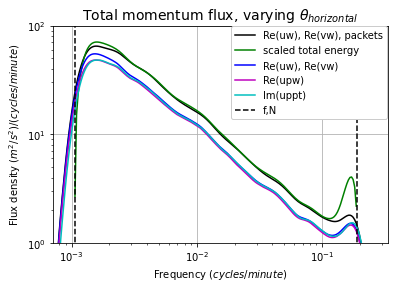

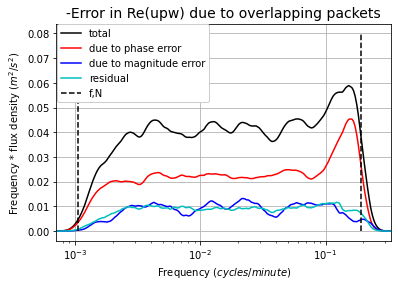

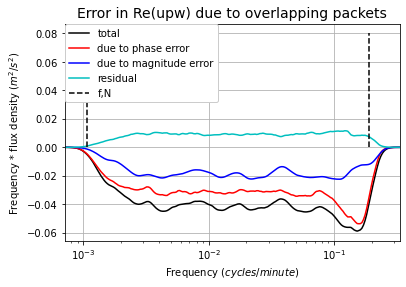

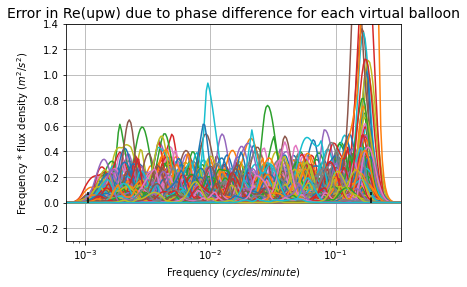

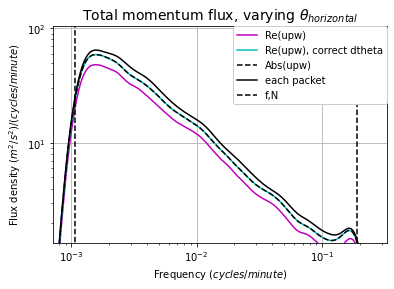

In [11]:
flux_spectrum = flux_spectrum_eachpacket[:,:,-1]
temp_flux = np.nanmean(flux_spectrum,axis=1)
temp_flux_eachpacket = np.nanmean(np.nansum(flux_spectrum_eachpacket[:,:,:-1],axis=2),axis=1)
temp_scaled_energy = np.nanmean(Etotal_scaled_spectrum,axis=1)
temp_flux_upw = np.nanmean(flux_spectrum_upw,axis=1)
temp_flux_uppt = np.nanmean(flux_spectrum_uppt,axis=1)
temp_flux_upw_correct_dtheta = np.nanmean(flux_spectrum_upw_correct_dtheta,axis=1)
temp_flux_upw_correct_UpW = np.nanmean(flux_spectrum_upw_correct_UpW,axis=1)
temp_flux_upw_eachpacket = np.nanmean(flux_spectrum_upw_eachpacket,axis=1)
temp_flux_absupw_eachpacket = np.nanmean(flux_spectrum_absupw_eachpacket,axis=1)
temp_flux_absupw = np.nanmean(flux_spectrum_absupw,axis=1)
temp_flux_uppt_eachpacket = np.nanmean(flux_spectrum_uppt_eachpacket,axis=1)
temp_flux_absuppt_eachpacket = np.nanmean(flux_spectrum_absuppt_eachpacket,axis=1)
temp_flux_absuppt = np.nanmean(flux_spectrum_absuppt,axis=1)



plt.figure(figsize=(6,4))
#ymin = 0.6*np.nanmin(temp_scaled_energy)
#ymax = 1.5*np.nanmax(temp_scaled_energy)
#ymax = 0.4
ymin = 1E0
ymax = 1E2
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot(frequency, temp_flux, 'b')
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'Total momentum flux, varying ${\theta}_{horizontal}$', fontsize=14)
#plt.title(r'Total momentum flux, fixed ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['Re(uw), Re(vw), packets','scaled total energy','Re(uw), Re(vw)',
            'Re(upw)','Im(uppt)','f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');



plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*(temp_flux_upw_eachpacket - temp_flux_upw), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw), 'b')
temp = temp_flux_upw_eachpacket - temp_flux_upw
temp = temp - (temp_flux_upw_correct_UpW - temp_flux_upw)
temp = temp - (temp_flux_upw_correct_dtheta - temp_flux_upw)
plt.plot(frequency, frequency*temp, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('-Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');



plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
#ymax = 0.08
plt.plot(frequency, frequency*(temp_flux_upw - temp_flux_upw_eachpacket), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket), 'b')
temp = temp_flux_upw - temp_flux_upw_eachpacket
temp = temp - (temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket)
temp = temp - (temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket)
plt.plot(frequency, frequency*temp, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');



plt.figure(figsize=(6,4))
temp = flux_spectrum_upw_correct_dtheta - flux_spectrum_upw
plt.plot(frequency, temp*np.tile(frequency,(n_balloons,1)).swapaxes(0,1))
temp = temp_flux_upw_eachpacket - temp_flux_upw
temp = temp - (temp_flux_upw_correct_dtheta - temp_flux_upw)
temp = temp - (temp_flux_upw_correct_UpW - temp_flux_upw)
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(-0.3,1.4)
plt.xscale('log')
plt.title('Error in Re(upw) due to phase difference for each virtual balloon', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$');

plt.figure(figsize=(6,4))
ymin = 0.8*np.nanmin(temp_scaled_energy)
ymax = 1.5*np.nanmax(temp_scaled_energy)
#ymax = 0.4
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_upw_correct_dtheta, 'c')
plt.plot(frequency, temp_flux_absupw, '--k')
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'Total momentum flux, varying ${\theta}_{horizontal}$', fontsize=14)
#plt.title(r'Total momentum flux, fixed ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['Re(upw)','Re(upw), correct dtheta','Abs(upw)','each packet','f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1);

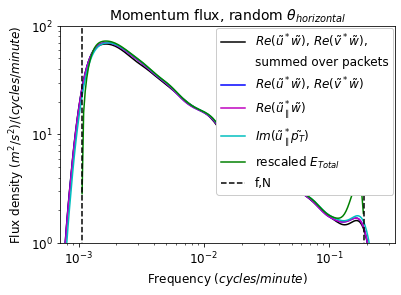

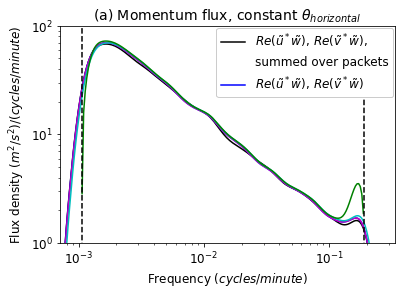

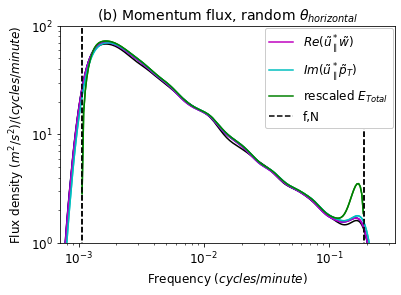

In [5]:
plt.figure(figsize=(6,4))
#ymin = 0.6*np.nanmin(temp_scaled_energy)
#ymax = 1.5*np.nanmax(temp_scaled_energy)
#ymax = 0.4
ymin = 1E0
ymax = 1E2
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot(frequency, temp_flux_eachpacket, 'w', alpha=0)
plt.plot(frequency, temp_flux, 'b')
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
#plt.title(r'Momentum flux, fixed ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$,',
            'summed over packets',
            r'$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$',
            r'$Re(\tilde{u}_\parallel^*\tilde{w})$',
            r'$Im(\tilde{u}_\parallel^*\tilde{p_T})$',
            'rescaled $E_{Total}$',
            'f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');







plt.figure(figsize=(6,4))
#ymin = 0.6*np.nanmin(temp_scaled_energy)
#ymax = 1.5*np.nanmax(temp_scaled_energy)
#ymax = 0.4
ymin = 1E0
ymax = 1E2
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot(frequency, temp_flux_eachpacket, 'w', alpha=0)
plt.plot(frequency, temp_flux, 'b')
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'(a) Momentum flux, constant ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$,',
            'summed over packets',
            r'$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1a.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymin = 0.6*np.nanmin(temp_scaled_energy)
#ymax = 1.5*np.nanmax(temp_scaled_energy)
#ymax = 0.4
ymin = 1E0
ymax = 1E2
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot(frequency, temp_flux, 'b')
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'(b) Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$Re(\tilde{u}_\parallel^*\tilde{w})$',
            r'$Im(\tilde{u}_\parallel^*\tilde{p}_T)$',
            r'rescaled $E_{Total}$',
            'f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1b.pdf', format='pdf', bbox_inches='tight');

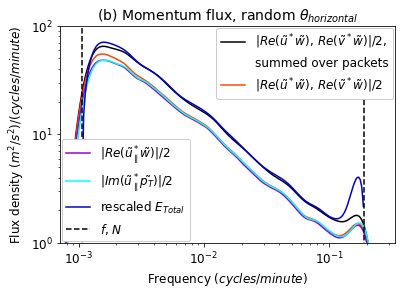

In [6]:
fig, ax = plt.subplots(figsize=(6,4))
ymin = 1E0
ymax = 1E2
line1, = ax.plot(frequency, temp_flux_eachpacket, 'k',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2,')
line2, = ax.plot(frequency, temp_flux_eachpacket, 'w', alpha=0,
                 label = 'summed over packets')
line3, = ax.plot(frequency, temp_flux, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line4, = ax.plot(frequency, temp_flux_upw, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line5, = ax.plot(frequency, temp_flux_uppt, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'|$Im(\tilde{u}_\parallel^*\tilde{p_T})$|/2')
line6, = ax.plot(frequency, temp_scaled_energy, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_title(r'(a) Momentum flux, constant ${\theta}_{horizontal}$', fontsize=14)
ax.set_title(r'(b) Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2, line3], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line4, line5, line6, line7],
          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1a.pdf', format='pdf', bbox_inches='tight');

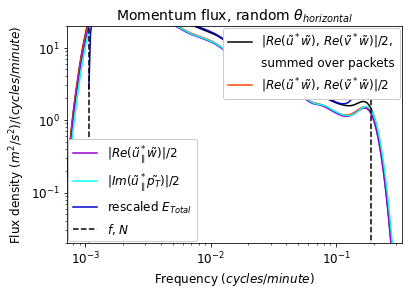

In [5]:
fig, ax = plt.subplots(figsize=(6,4))
ymin = 2E-2
ymax = 2E1
line1, = ax.plot(frequency, temp_flux_eachpacket, 'k',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2,')
line2, = ax.plot(frequency, temp_flux_eachpacket, 'w', alpha=0,
                 label = 'summed over packets')
line3, = ax.plot(frequency, temp_flux, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line4, = ax.plot(frequency, temp_flux_upw, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line5, = ax.plot(frequency, temp_flux_uppt, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'|$Im(\tilde{u}_\parallel^*\tilde{p_T})$|/2')
line6, = ax.plot(frequency, temp_scaled_energy, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2, line3], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line4, line5, line6, line7],
          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1c.pdf', format='pdf', bbox_inches='tight');

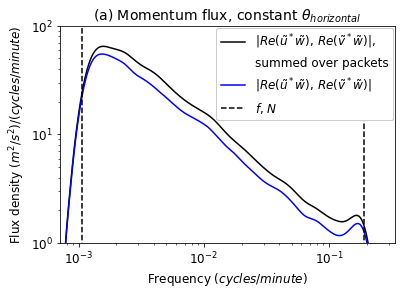

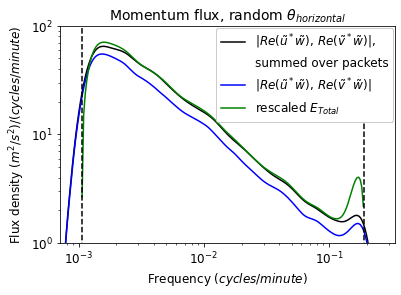

In [19]:
fig, ax = plt.subplots(figsize=(6,4))
ymin = 1E0
ymax = 1E2
line1, = ax.plot(frequency, temp_flux_eachpacket, 'k',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|,')
line2, = ax.plot(frequency, temp_flux_eachpacket, 'w', alpha=0,
                 label = 'summed over packets')
line3, = ax.plot(frequency, temp_flux, 'b',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'(a) Momentum flux, constant ${\theta}_{horizontal}$', fontsize=14)
#ax.set_title(r'(b) Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2, line3, line7], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend);
#ax.legend(handles=[line4, line5, line6, line7],
#          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp15a.pdf', format='pdf', bbox_inches='tight');



fig, ax = plt.subplots(figsize=(6,4))
ymin = 1E0
ymax = 1E2
line1, = ax.plot(frequency, temp_flux_eachpacket, 'k',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|,')
line2, = ax.plot(frequency, temp_flux_eachpacket, 'w', alpha=0,
                 label = 'summed over packets')
line3, = ax.plot(frequency, temp_flux, 'b',
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|')
line6, = ax.plot(frequency, temp_scaled_energy, 'g',
                 label = r'rescaled $E_{Total}$')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title(r'Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
#ax.set_title(r'(b) Momentum flux, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2, line3, line6], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend);
#ax.legend(handles=[line4, line5, line6, line7],
#          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
plt.savefig('../plots/temp17b.pdf', format='pdf', bbox_inches='tight');

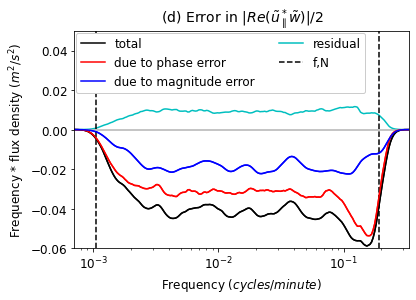

In [24]:
plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
plt.plot(frequency, frequency*(temp_flux_upw - temp_flux_upw_eachpacket), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket), 'b')
temp = temp_flux_upw - temp_flux_upw_eachpacket
temp = temp - (temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket)
temp = temp - (temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket)
plt.plot(frequency, frequency*temp, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [-ymax, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [-ymax, ymax],'--k')
plt.plot([np.abs(60*f/(2*np.pi))/1.5,1/3],[0, 0], color = [0.7,0.7,0.7])
plt.plot(frequency, frequency*(temp_flux_upw - temp_flux_upw_eachpacket), 'k')
plt.plot(frequency, frequency*(temp_flux_upw_correct_UpW - temp_flux_upw_eachpacket), 'r')
plt.plot(frequency, frequency*(temp_flux_upw_correct_dtheta - temp_flux_upw_eachpacket), 'b')
#plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(-0.06, 0.05)
plt.xscale('log')
plt.title(r'(d) Error in |$Re(\tilde{u}_\parallel^*\tilde{w})$|/2', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12)
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            ncol=2, loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

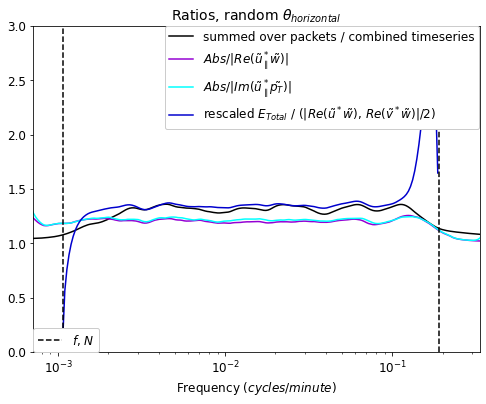

In [18]:
#fig, ax = plt.subplots(figsize=(6,4))
fig, ax = plt.subplots(figsize=(8,6))
ymin = 1E0
ymax = 1E2
line1, = ax.plot(frequency, temp_flux_eachpacket / temp_flux, 'k',
                 label = 'summed over packets / combined timeseries')
line4, = ax.plot(frequency, temp_flux_absupw / temp_flux_upw, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'$Abs / |Re(\tilde{u}_\parallel^*\tilde{w})$|')
line5, = ax.plot(frequency, temp_flux_absuppt / temp_flux_uppt, c=matplotlib.colors.CSS4_COLORS['cyan'],
                 label = r'$Abs / |Im(\tilde{u}_\parallel^*\tilde{p_T})$|')
line6, = ax.plot(frequency, temp_scaled_energy / temp_flux, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$ / (|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2)')
line7, = ax.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k',
                 label = r'$f$, $N$')
ax.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
ax.set_xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
ax.set_ylim(0,3)
ax.set_xscale('log')
#ax.set_yscale('log')
#ax.set_title(r'(a) Momentum flux, constant ${\theta}_{horizontal}$', fontsize=14)
ax.set_title(r'Ratios, random ${\theta}_{horizontal}$', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
#ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line4, line5, line6], 
                         loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line7],
          loc='lower left', bbox_to_anchor=(-0.013, -0.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp1a.pdf', format='pdf', bbox_inches='tight');

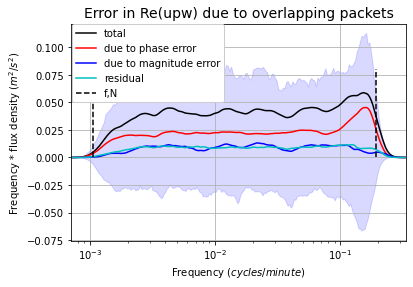

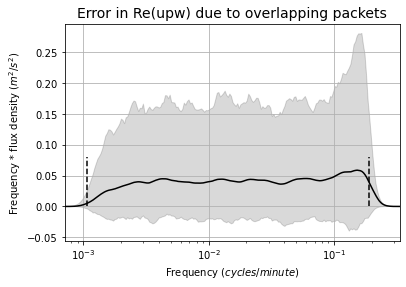

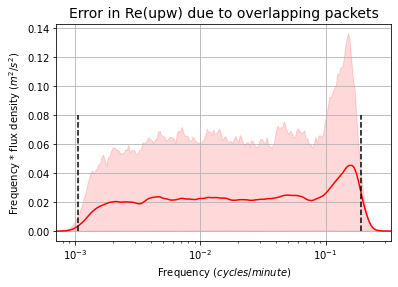

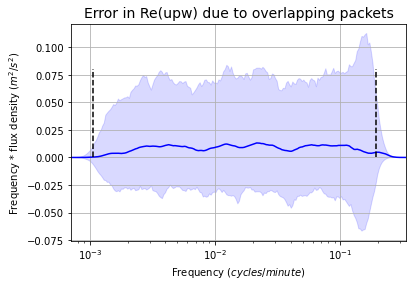

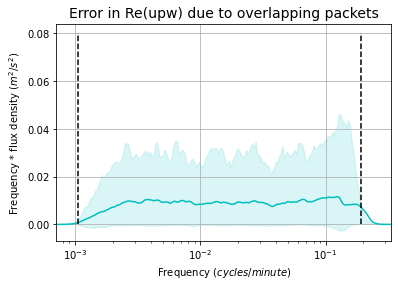

In [15]:
error_total = flux_spectrum_upw_eachpacket - flux_spectrum_upw
error_dtheta = flux_spectrum_upw_correct_dtheta - flux_spectrum_upw
error_UpW = flux_spectrum_upw_correct_UpW - flux_spectrum_upw
error_corr = error_total - error_dtheta - error_UpW

quant_low = 0.1
quant_high = 0.9

error_total_quant_low = np.nanquantile(error_total, quant_low, axis=1)
error_dtheta_quant_low = np.nanquantile(error_dtheta, quant_low, axis=1)
error_UpW_quant_low = np.nanquantile(error_UpW, quant_low, axis=1)
error_corr_quant_low = np.nanquantile(error_corr, quant_low, axis=1)

error_total_quant_high = np.nanquantile(error_total, quant_high, axis=1)
error_dtheta_quant_high = np.nanquantile(error_dtheta, quant_high, axis=1)
error_UpW_quant_high = np.nanquantile(error_UpW, quant_high, axis=1)
error_corr_quant_high = np.nanquantile(error_corr, quant_high, axis=1)

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_total, axis=1), 'k')
plt.plot(frequency, frequency*np.mean(error_dtheta, axis=1), 'r')
plt.plot(frequency, frequency*np.mean(error_UpW, axis=1), 'b')
plt.plot(frequency, frequency*np.mean(error_corr, axis=1), 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
#plt.fill_between(frequency, frequency*error_total_quant_low, frequency*error_total_quant_high, color='k', alpha=0.15)
#plt.fill_between(frequency, frequency*error_dtheta_quant_low, frequency*error_dtheta_quant_high, color='r', alpha=0.15)
plt.fill_between(frequency, frequency*error_UpW_quant_low, frequency*error_UpW_quant_high, color='b', alpha=0.15)
#plt.fill_between(frequency, frequency*error_corr_quant_low, frequency*error_corr_quant_high, color='c', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_total, axis=1), 'k')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_total_quant_low, frequency*error_total_quant_high, color='k', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_dtheta, axis=1), 'r')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_dtheta_quant_low, frequency*error_dtheta_quant_high, color='r', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_UpW, axis=1), 'b')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_UpW_quant_low, frequency*error_UpW_quant_high, color='b', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_corr, axis=1), 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_corr_quant_low, frequency*error_corr_quant_high, color='c', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$');
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

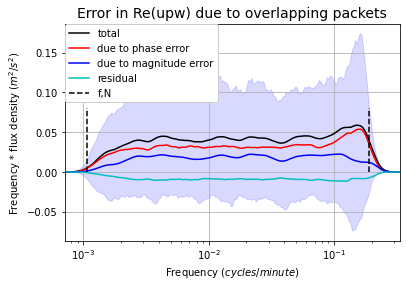

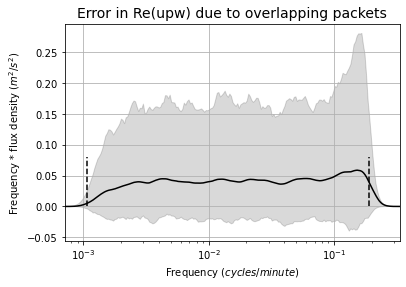

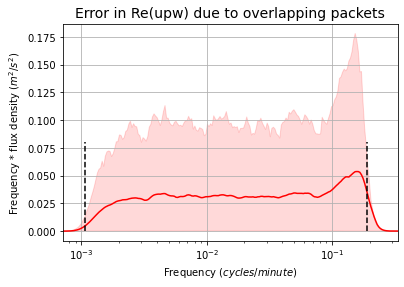

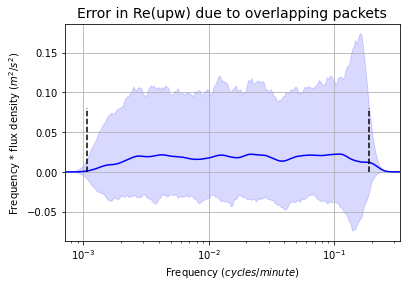

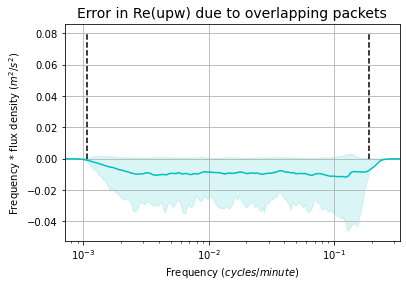

In [52]:
error_total = flux_spectrum_upw_eachpacket - flux_spectrum_upw
error_dtheta = flux_spectrum_upw_eachpacket - flux_spectrum_upw_correct_UpW
error_UpW = flux_spectrum_upw_eachpacket - flux_spectrum_upw_correct_dtheta
error_corr = error_total - error_dtheta - error_UpW

quant_low = 0.1
quant_high = 0.9

error_total_quant_low = np.nanquantile(error_total, quant_low, axis=1)
error_dtheta_quant_low = np.nanquantile(error_dtheta, quant_low, axis=1)
error_UpW_quant_low = np.nanquantile(error_UpW, quant_low, axis=1)
error_corr_quant_low = np.nanquantile(error_corr, quant_low, axis=1)

error_total_quant_high = np.nanquantile(error_total, quant_high, axis=1)
error_dtheta_quant_high = np.nanquantile(error_dtheta, quant_high, axis=1)
error_UpW_quant_high = np.nanquantile(error_UpW, quant_high, axis=1)
error_corr_quant_high = np.nanquantile(error_corr, quant_high, axis=1)

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_total, axis=1), 'k')
plt.plot(frequency, frequency*np.mean(error_dtheta, axis=1), 'r')
plt.plot(frequency, frequency*np.mean(error_UpW, axis=1), 'b')
plt.plot(frequency, frequency*np.mean(error_corr, axis=1), 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
#plt.fill_between(frequency, frequency*error_total_quant_low, frequency*error_total_quant_high, color='k', alpha=0.15)
#plt.fill_between(frequency, frequency*error_dtheta_quant_low, frequency*error_dtheta_quant_high, color='r', alpha=0.15)
plt.fill_between(frequency, frequency*error_UpW_quant_low, frequency*error_UpW_quant_high, color='b', alpha=0.15)
#plt.fill_between(frequency, frequency*error_corr_quant_low, frequency*error_corr_quant_high, color='c', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
plt.legend(['total','due to phase error','due to magnitude error','residual','f,N'],
            loc='upper left', bbox_to_anchor=(-0.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_total, axis=1), 'k')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_total_quant_low, frequency*error_total_quant_high, color='k', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_dtheta, axis=1), 'r')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_dtheta_quant_low, frequency*error_dtheta_quant_high, color='r', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_UpW, axis=1), 'b')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_UpW_quant_low, frequency*error_UpW_quant_high, color='b', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$')
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
#ymax = 1.1*np.nanmax(frequency*(temp_flux_upw_eachpacket - temp_flux_upw))
ymax = 0.08
#ymax = 0.007
plt.plot(frequency, frequency*np.mean(error_corr, axis=1), 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.fill_between(frequency, frequency*error_corr_quant_low, frequency*error_corr_quant_high, color='c', alpha=0.15)
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
#plt.ylim(0,ymax)
plt.xscale('log')
plt.title('Error in Re(upw) due to overlapping packets', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Frequency * flux density $(m^{2}/s^{2})$');
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

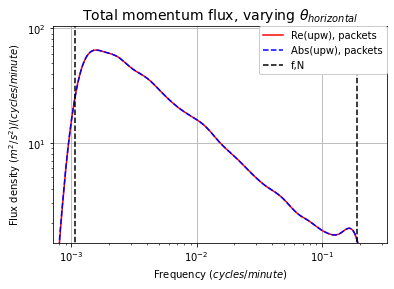

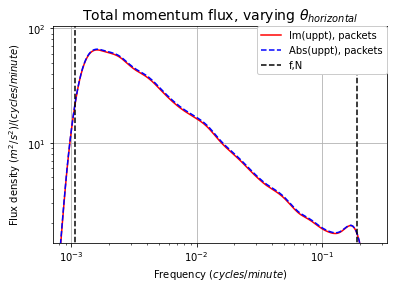

In [14]:
plt.figure(figsize=(6,4))
ymin = 0.8*np.nanmin(temp_scaled_energy)
ymax = 1.5*np.nanmax(temp_scaled_energy)
plt.plot(frequency, temp_flux_upw_eachpacket, 'r')
plt.plot(frequency, temp_flux_absupw_eachpacket, '--b')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'Total momentum flux, varying ${\theta}_{horizontal}$', fontsize=14)
#plt.title(r'Total momentum flux, fixed ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['Re(upw), packets','Abs(upw), packets','f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(6,4))
ymin = 0.8*np.nanmin(temp_scaled_energy)
ymax = 1.5*np.nanmax(temp_scaled_energy)
plt.plot(frequency, temp_flux_uppt_eachpacket, 'r')
plt.plot(frequency, temp_flux_absuppt_eachpacket, '--b')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, ymax],'--k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, ymax],'--k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/1.5,1/3)
plt.ylim(ymin,ymax)
plt.xscale('log')
plt.yscale('log')
plt.title(r'Total momentum flux, varying ${\theta}_{horizontal}$', fontsize=14)
#plt.title(r'Total momentum flux, fixed ${\theta}_{horizontal}$', fontsize=14)
plt.xlabel('Frequency $(cycles/minute)$')
plt.ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$')
plt.legend(['Im(uppt), packets','Abs(uppt), packets','f,N'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

### Probability distributions of the ratio of output to input energy, momentum flux

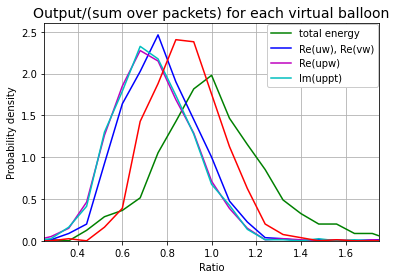

In [23]:
flux_total_ratio = flux_total_eachpacket[:,-1]/np.sum(flux_total_eachpacket[:,:-1],axis=1)
Etotal_ratio = Etotal_total[:,-1]/np.sum(Etotal_total[:,:-1],axis=1)
flux_upw_ratio = flux_total_upw/flux_total_upw_eachpacket
flux_uppt_ratio = flux_total_uppt/flux_total_uppt_eachpacket
UpW_ratio = flux_total_absupw/flux_total_absupw_eachpacket

n_bins = 25
bin_min = 0
bin_max = 2
bin_res = (bin_max - bin_min)/n_bins
bins = bin_min + bin_res*np.arange(1 + n_bins)
bin_centers = 0.5*(bins[:-1] + bins[1:])

hist, _ = np.histogram(flux_total_ratio, bins = bins)
pdf_flux_total_ratio = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(Etotal_ratio, bins = bins)
pdf_Etotal_ratio = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(flux_upw_ratio, bins = bins)
pdf_flux_upw_ratio = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(flux_uppt_ratio, bins = bins)
pdf_flux_uppt_ratio = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(UpW_ratio, bins = bins)
pdf_UpW_ratio = hist/(bin_res*np.sum(hist))



plt.figure(figsize=(6,4))
plt.plot(bin_centers, pdf_Etotal_ratio, 'g')
plt.plot(bin_centers, pdf_flux_total_ratio, 'b')
plt.plot(bin_centers, pdf_flux_upw_ratio, 'm')
plt.plot(bin_centers, pdf_flux_uppt_ratio, 'c')
plt.plot(bin_centers, pdf_UpW_ratio, 'r')
plt.grid()
plt.xlim(bin_min, bin_max)
plt.xlim(0.25, 1.75)
plt.ylim(0,2.6)
plt.title('Output/(sum over packets) for each virtual balloon', fontsize=14)
plt.xlabel('Ratio')
plt.ylabel('Probability density')
plt.legend(['total energy','Re(uw), Re(vw)','Re(upw)','Im(uppt)'],
           loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1);
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

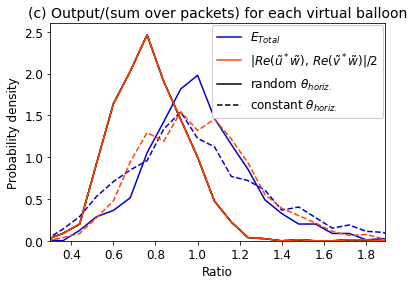

In [29]:
container = np.load('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq.npz')
data = [container[key] for key in container]
Etotal_total1                   = data[23]  # (n_balloons)
flux_total_eachpacket1          = data[10] # (n_balloons, n_packet_frequencies+1)

container = np.load('GaussEnv_ThHpiover6_1000B_20P_8omega0.npz')
data = [container[key] for key in container]
Etotal_total2                   = data[21]  # (n_balloons)
flux_total_eachpacket2          = data[10] # (n_balloons, n_packet_frequencies+1)

flux_total_ratio1 = flux_total_eachpacket1[:,-1]/np.sum(flux_total_eachpacket1[:,:-1],axis=1)
Etotal_ratio1 = Etotal_total1[:,-1]/np.sum(Etotal_total1[:,:-1],axis=1)
flux_total_ratio2 = flux_total_eachpacket2[:,-1]/np.sum(flux_total_eachpacket2[:,:-1],axis=1)
Etotal_ratio2 = Etotal_total2[:,-1]/np.sum(Etotal_total2[:,:-1],axis=1)

n_bins = 25
bin_min = 0
bin_max = 2
bin_res = (bin_max - bin_min)/n_bins
bins = bin_min + bin_res*np.arange(1 + n_bins)
bin_centers = 0.5*(bins[:-1] + bins[1:])

hist, _ = np.histogram(flux_total_ratio1, bins = bins)
pdf_flux_total_ratio1 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(Etotal_ratio1, bins = bins)
pdf_Etotal_ratio1 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(flux_total_ratio2, bins = bins)
pdf_flux_total_ratio2 = hist/(bin_res*np.sum(hist))

hist, _ = np.histogram(Etotal_ratio2, bins = bins)
pdf_Etotal_ratio2 = hist/(bin_res*np.sum(hist))



plt.figure(figsize=(6,4))
plt.plot(bin_centers, pdf_Etotal_ratio1, c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.plot(bin_centers, pdf_flux_total_ratio1, c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(bin_centers, pdf_flux_total_ratio1, 'k')
plt.plot(bin_centers, pdf_flux_total_ratio1, '--k')
plt.plot(bin_centers, pdf_Etotal_ratio2, c=matplotlib.colors.CSS4_COLORS['mediumblue'], linestyle='--')
plt.plot(bin_centers, pdf_flux_total_ratio2, c=matplotlib.colors.CSS4_COLORS['orangered'], linestyle='--')
plt.plot(bin_centers, pdf_flux_total_ratio1, c=matplotlib.colors.CSS4_COLORS['orangered'])
#plt.grid()
plt.xlim(bin_min, bin_max)
plt.xlim(0.3, 1.89)
plt.ylim(0,2.6)
plt.title('(c) Output/(sum over packets) for each virtual balloon', fontsize=14)
plt.xlabel('Ratio', fontsize=12)
plt.ylabel('Probability density', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'$E_{Total}$',
            r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2',
            r'random ${\theta}_{horiz.}$',
            r'constant ${\theta}_{horiz.}$'],
           loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');

(0.8869018893197694,
 0.16773389419738735,
 0.9642522299375434,
 1.0040655755705894,
 0.9685454689908777)

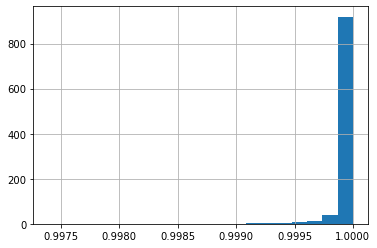

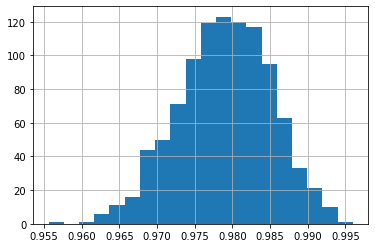

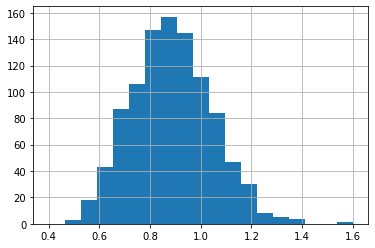

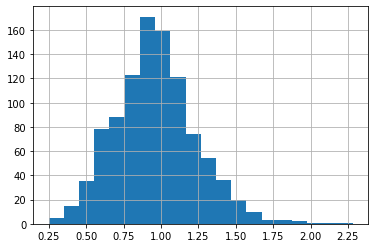

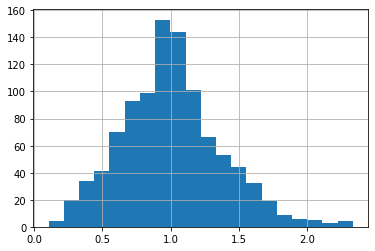

In [7]:
temp1 = flux_total_upw_eachpacket/flux_total_absupw_eachpacket
temp2 = flux_total_uppt_eachpacket/flux_total_absuppt_eachpacket
temp3 = flux_total_absupw/flux_total_absupw_eachpacket
temp4 = up_power_total[:,-1]/np.sum(up_power_total[:,:-1],axis=1)
temp5 = Ekv_total[:,-1]/np.sum(Ekv_total[:,:-1],axis=1)

plt.figure()
plt.hist(temp1,20)
plt.grid();

plt.figure()
plt.hist(temp2,20)
plt.grid();

plt.figure()
plt.hist(temp3,bins=np.linspace(0.4,1.6,20))
plt.grid();

plt.figure()
plt.hist(temp4,20)
plt.grid();

plt.figure()
plt.hist(temp5,20)
plt.grid();

np.mean(temp3), np.std(temp3), np.mean(temp4), np.mean(temp5), np.mean(temp4*temp5)

### Old calculations and plots

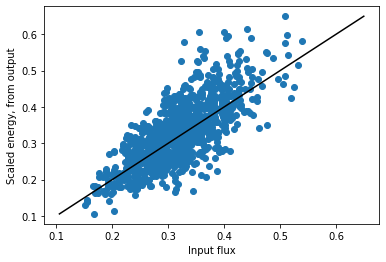

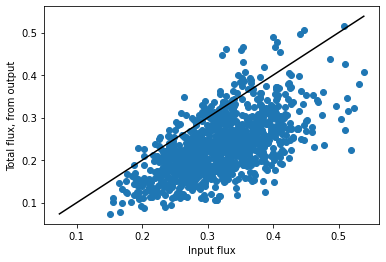

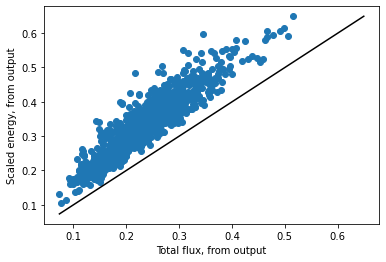

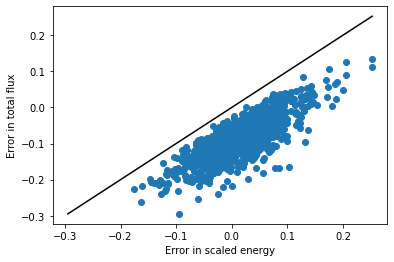

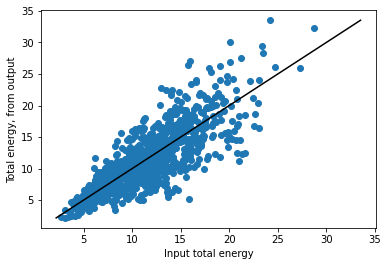

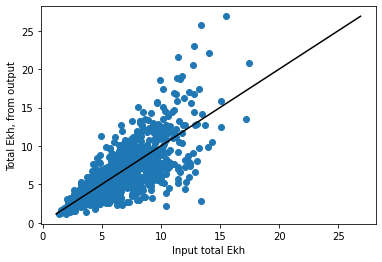

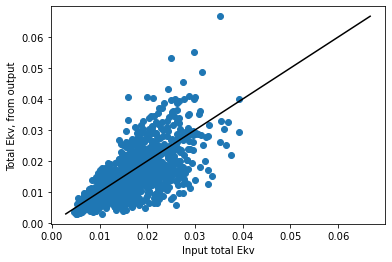

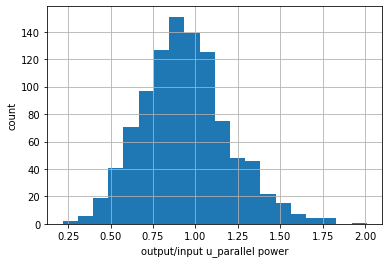

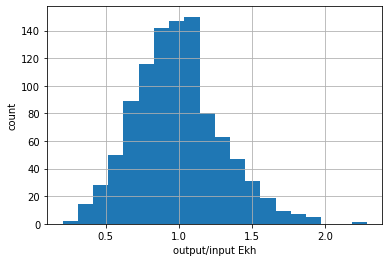

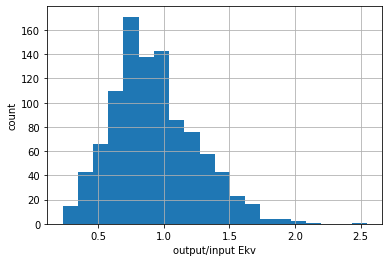

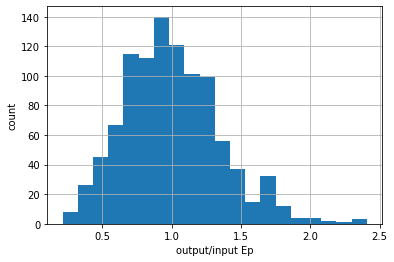

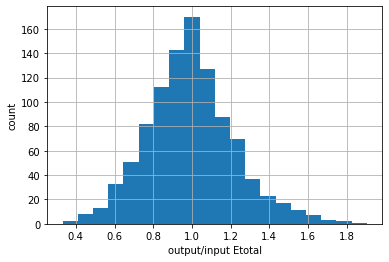

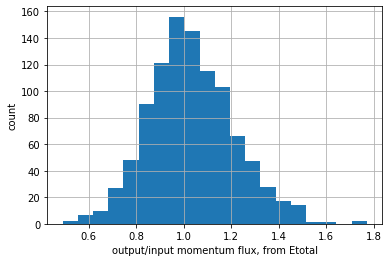

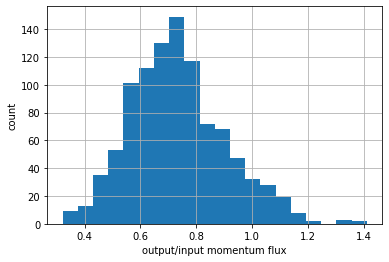

In [11]:
flux_total = flux_total_eachpacket[:,-1]
temp = np.sum(total_flux_packets,axis=0)

plt.figure()
minval = min(np.min(temp),np.min(Etotal_scaled_total))
maxval = max(np.max(temp),np.max(Etotal_scaled_total))
plt.scatter(temp,Etotal_scaled_total)
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Input flux')
plt.ylabel('Scaled energy, from output');

plt.figure()
minval = min(np.min(temp),np.min(flux_total))
maxval = max(np.max(temp),np.max(flux_total))
plt.scatter(temp,flux_total)
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Input flux')
plt.ylabel('Total flux, from output');

plt.figure()
minval = min(np.min(flux_total),np.min(Etotal_scaled_total))
maxval = max(np.max(flux_total),np.max(Etotal_scaled_total))
plt.scatter(flux_total,Etotal_scaled_total)
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Total flux, from output')
plt.ylabel('Scaled energy, from output');

plt.figure()
temp1 = Etotal_scaled_total - temp
temp2 = flux_total - temp
minval = min(np.min(temp1),np.min(temp2))
maxval = max(np.max(temp1),np.max(temp2))
plt.scatter(temp1,temp2)
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Error in scaled energy')
plt.ylabel('Error in total flux');

#temp = np.sum(Ekh_packets + Ekv_packets + Ep_packets,axis=0)
temp = np.sum(total_energy_packets,axis=0)
plt.figure()
minval = min(np.min(temp),np.min(Etotal_total[:,-1]))
maxval = max(np.max(temp),np.max(Etotal_total[:,-1]))
plt.scatter(temp,Etotal_total[:,-1])
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Input total energy')
plt.ylabel('Total energy, from output');

temp = np.sum(Ekh_packets,axis=0)
plt.figure()
minval = min(np.min(temp),np.min(Ekh_total[:,-1]))
maxval = max(np.max(temp),np.max(Ekh_total[:,-1]))
plt.scatter(temp,Ekh_total[:,-1])
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Input total Ekh')
plt.ylabel('Total Ekh, from output');

temp = np.sum(Ekv_packets,axis=0)
plt.figure()
minval = min(np.min(temp),np.min(Ekv_total[:,-1]))
maxval = max(np.max(temp),np.max(Ekv_total[:,-1]))
plt.scatter(temp,Ekv_total[:,-1])
plt.plot([minval,maxval],[minval,maxval],'-k')
plt.xlabel('Input total Ekv')
plt.ylabel('Total Ekv, from output');

plt.figure()
temp = np.sum(up_power_total[:,:-1],axis=1)
temp = up_power_total[:,-1]/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input u_parallel power')
plt.ylabel('count');

plt.figure()
temp = np.sum(Ekh_packets,axis=0)
temp = Ekh_total[:,-1]/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input Ekh')
plt.ylabel('count');

plt.figure()
temp = np.sum(Ekv_packets,axis=0)
temp = Ekv_total[:,-1]/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input Ekv')
plt.ylabel('count');

plt.figure()
temp = np.sum(Ep_packets,axis=0)
temp = Ep_total[:,-1]/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input Ep')
plt.ylabel('count');

plt.figure()
temp = np.sum(Ekh_packets + Ekv_packets + Ep_packets,axis=0)
temp = Etotal_total[:,-1]/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input Etotal')
plt.ylabel('count');

plt.figure()
temp = np.sum(total_flux_packets,axis=0)
temp = Etotal_scaled_total/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input momentum flux, from Etotal')
plt.ylabel('count');

plt.figure()
temp = np.sum(total_flux_packets,axis=0)
temp = flux_total/temp
plt.hist(temp,20)
plt.grid()
plt.xlabel('output/input momentum flux')
plt.ylabel('count');

In [12]:
temp = np.sum(up_power_total[:,:-1])
print(np.sum(up_power_total[:,-1])/temp)

temp = np.sum(Ekh_total[:,:-1])
print(np.sum(Ekh_total[:,-1])/temp)

temp = np.sum(Ekv_total[:,:-1])
print(np.sum(Ekv_total[:,-1])/temp)

0.9363658532158807
0.9879710460338009
1.016998277264904


From each packet: 38.88031723079979
Total momentum flux, from combined timeseries: 28.444185431523724
Total momentum flux, from packet timeseries: 37.876973299355825
From scaled energy: 40.17039421669807
From re(upw): 27.061111796311202
From re(upw), summed over each packet: 37.8674225516411
From im(uppt): 28.40628764759502
From im(uppt), summed over each packet: 39.87321526899099
From Abs(upw): 33.280095033850785
From Abs(uppt): 34.841838677776764

Error in re(upw) due to superposition of packets: -10.806310755329893
attributed to errors in dtheta: -6.045290796891601
attributed to errors in UpW: -2.505115554781591
attributed to correlated dtheta, UpW errors: -2.2559044036567

Error in im(uppt) due to superposition of packets: -11.466927621395973
attributed to errors in dtheta: -6.271744062757929
attributed to errors in UpPT: -2.8064620618517284
attributed to correlated dtheta, UpPT errors: -2.3887214967863155



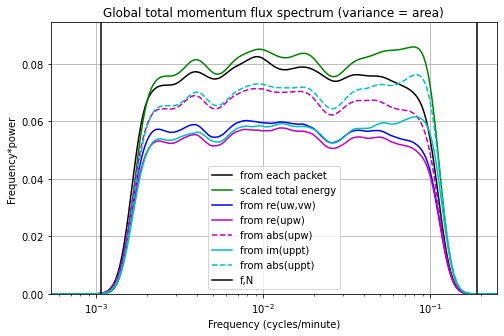

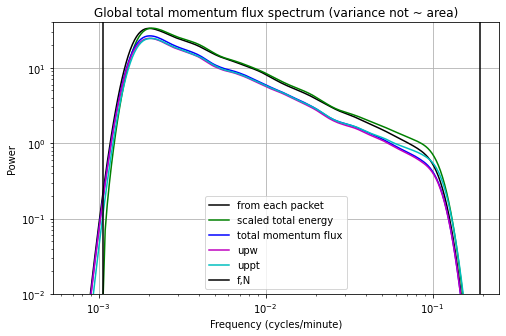

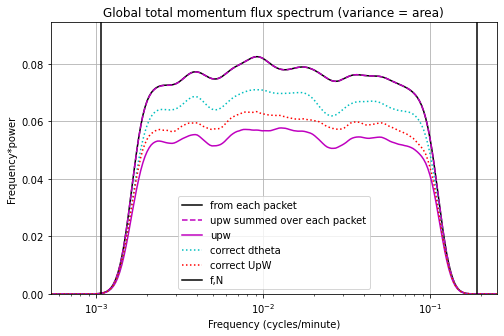

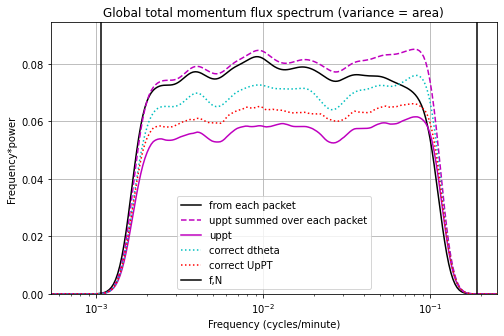

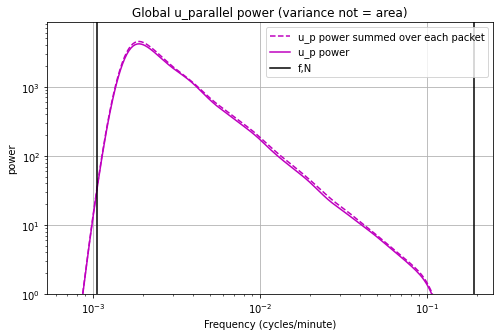

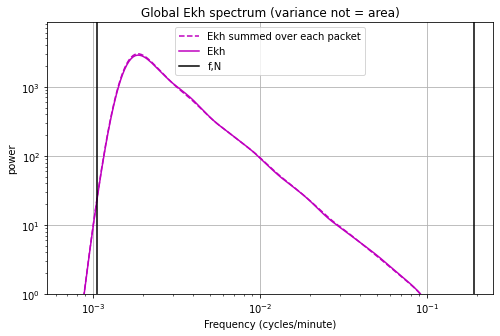

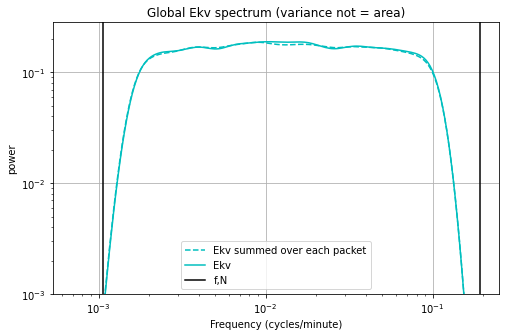

In [15]:
flux_spectrum = flux_spectrum_eachpacket[:,:,-1]
temp_flux = np.nanmean(flux_spectrum,axis=1)
temp_flux_eachpacket = np.nanmean(np.nansum(flux_spectrum_eachpacket[:,:,:-1],axis=2),axis=1)
temp_scaled_energy = np.nanmean(Etotal_scaled_spectrum,axis=1)
temp_flux_upw = np.nanmean(flux_spectrum_upw,axis=1)
temp_flux_uppt = np.nanmean(flux_spectrum_uppt,axis=1)
temp_flux_absupw = np.nanmean(flux_spectrum_absupw,axis=1)
temp_flux_absuppt = np.nanmean(flux_spectrum_absuppt,axis=1)
temp_flux_upw_correct_dtheta = np.nanmean(flux_spectrum_upw_correct_dtheta,axis=1)
temp_flux_upw_correct_UpW = np.nanmean(flux_spectrum_upw_correct_UpW,axis=1)
temp_flux_upw_eachpacket = np.nanmean(flux_spectrum_upw_eachpacket,axis=1)
temp_flux_uppt_correct_dtheta = np.nanmean(flux_spectrum_uppt_correct_dtheta,axis=1)
temp_flux_uppt_correct_UpPT = np.nanmean(flux_spectrum_uppt_correct_UpPT,axis=1)
temp_flux_uppt_eachpacket = np.nanmean(flux_spectrum_uppt_eachpacket,axis=1)
temp_Ekh = np.nanmean(Ekh_spectrum[:,:,-1],axis=1)
temp_Ekh_eachpacket = np.nanmean(np.nansum(Ekh_spectrum[:,:,:-1],axis=2),axis=1)
temp_Ekv = np.nanmean(Ekv_spectrum[:,:,-1],axis=1)
temp_Ekv_eachpacket = np.nanmean(np.nansum(Ekv_spectrum[:,:,:-1],axis=2),axis=1)
temp_up_power = np.nanmean(up_power_spectrum[:,:,-1],axis=1)
temp_up_power_eachpacket = np.nanmean(np.nansum(up_power_spectrum[:,:,:-1],axis=2),axis=1)

print('From each packet:',1000*rho_bar*np.nanmean(np.sum(total_flux_packets,axis=0)))
print('Total momentum flux, from combined timeseries:',1000*rho_bar*np.nanmean(flux_total))
print('Total momentum flux, from packet timeseries:',1000*rho_bar*np.nanmean(np.nansum(flux_total_eachpacket[:,:-1],axis=1)))
print('From scaled energy:',1000*rho_bar*np.nanmean(Etotal_scaled_total))
print('From re(upw):',1000*rho_bar*np.nanmean(flux_total_upw))
print('From re(upw), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_upw_eachpacket))
print('From im(uppt):',1000*rho_bar*np.nanmean(flux_total_uppt))
print('From im(uppt), summed over each packet:',1000*rho_bar*np.nanmean(flux_total_uppt_eachpacket))
print('From Abs(upw):',1000*rho_bar*np.nanmean(flux_total_absupw))
print('From Abs(uppt):',1000*rho_bar*np.nanmean(flux_total_absuppt))
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket))
print('Error in re(upw) due to superposition of packets:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
print('attributed to errors in UpW:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_correct_UpW))
temp = 1000*rho_bar*(np.nanmean(flux_total_upw) - np.nanmean(flux_total_upw_eachpacket)) - temp
print('attributed to correlated dtheta, UpW errors:', temp)
print()

temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket))
print('Error in im(uppt) due to superposition of packets:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
print('attributed to errors in dtheta:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
print('attributed to errors in UpPT:', temp)
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_dtheta))
temp = temp + 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_correct_UpPT))
temp = 1000*rho_bar*(np.nanmean(flux_total_uppt) - np.nanmean(flux_total_uppt_eachpacket)) - temp
print('attributed to correlated dtheta, UpPT errors:', temp)
print()


# Plot
# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_flux_eachpacket, 'k')
plt.plot(frequency, frequency*temp_scaled_energy, 'g')
plt.plot(frequency, frequency*temp_flux, 'b')
plt.plot(frequency, frequency*temp_flux_upw, 'm')
plt.plot(frequency, frequency*temp_flux_absupw, '--m')
plt.plot(frequency, frequency*temp_flux_uppt, 'c')
plt.plot(frequency, frequency*temp_flux_absuppt, '--c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(0,1.1*np.nanmax(frequency*temp_scaled_energy))
plt.xscale('log')
plt.title('Global total momentum flux spectrum (variance = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Frequency*power')
plt.legend(['from each packet','scaled total energy','from re(uw,vw)',
            'from re(upw)','from abs(upw)','from im(uppt)','from abs(uppt)','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# log(power) vs. log(frequency) (This method does not have variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, temp_flux_eachpacket, 'k')
plt.plot(frequency, temp_scaled_energy, 'g')
plt.plot(frequency, temp_flux, 'b')
plt.plot(frequency, temp_flux_upw, 'm')
plt.plot(frequency, temp_flux_uppt, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.2*np.nanmax(temp_scaled_energy)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.2*np.nanmax(temp_scaled_energy)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-2,1.2*np.nanmax(temp_scaled_energy))
plt.xscale('log')
plt.yscale('log')
plt.title('Global total momentum flux spectrum (variance not ~ area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Power')
plt.legend(['from each packet','scaled total energy','total momentum flux','upw','uppt','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_flux_eachpacket, 'k')
plt.plot(frequency, frequency*temp_flux_upw_eachpacket, '--m')
plt.plot(frequency, frequency*temp_flux_upw, 'm')
plt.plot(frequency, frequency*temp_flux_upw_correct_dtheta, ':c')
plt.plot(frequency, frequency*temp_flux_upw_correct_UpW, ':r')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(0,1.1*np.nanmax(frequency*temp_scaled_energy))
plt.xscale('log')
plt.title('Global total momentum flux spectrum (variance = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Frequency*power')
plt.legend(['from each packet','upw summed over each packet','upw','correct dtheta','correct UpW','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_flux_eachpacket, 'k')
plt.plot(frequency, frequency*temp_flux_uppt_eachpacket, '--m')
plt.plot(frequency, frequency*temp_flux_uppt, 'm')
plt.plot(frequency, frequency*temp_flux_uppt_correct_dtheta, ':c')
plt.plot(frequency, frequency*temp_flux_uppt_correct_UpPT, ':r')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.1*np.nanmax(frequency*temp_scaled_energy)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(0,1.1*np.nanmax(frequency*temp_scaled_energy))
plt.xscale('log')
plt.title('Global total momentum flux spectrum (variance = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Frequency*power')
plt.legend(['from each packet','uppt summed over each packet','uppt','correct dtheta','correct UpPT','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, temp_up_power_eachpacket, '--m')
plt.plot(frequency, temp_up_power, 'm')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-0,3*np.nanmax(temp_Ekh))
plt.xscale('log')
plt.yscale('log')
plt.title('Global u_parallel power (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['u_p power summed over each packet','u_p power','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, temp_Ekh_eachpacket, '--m')
plt.plot(frequency, temp_Ekh, 'm')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-0,3*np.nanmax(temp_Ekh))
plt.xscale('log')
plt.yscale('log')
plt.title('Global Ekh spectrum (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['Ekh summed over each packet','Ekh','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, temp_Ekv_eachpacket, '--c')
plt.plot(frequency, temp_Ekv, 'c')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.5*np.nanmax(temp_Ekv)],'k')
plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.5*np.nanmax(temp_Ekv)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-3,1.5*np.nanmax(temp_Ekv))
plt.xscale('log')
plt.yscale('log')
plt.title('Global Ekv spectrum (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['Ekv summed over each packet','Ekv','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

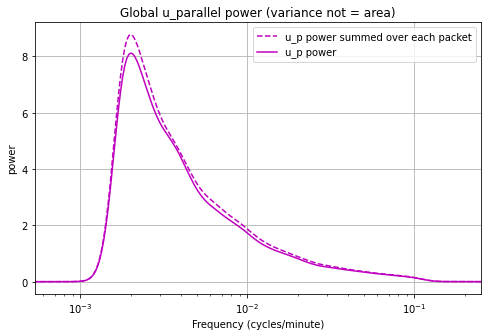

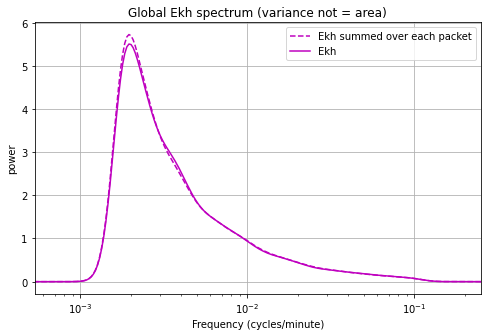

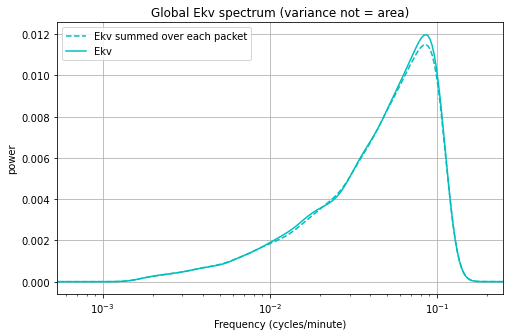

In [16]:
# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_up_power_eachpacket, '--m')
plt.plot(frequency, frequency*temp_up_power, 'm')
#plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
#plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
#plt.ylim(1E-0,3*np.nanmax(temp_Ekh))
plt.xscale('log')
#plt.yscale('log')
plt.title('Global u_parallel power (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['u_p power summed over each packet','u_p power','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_Ekh_eachpacket, '--m')
plt.plot(frequency, frequency*temp_Ekh, 'm')
#plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
#plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 3*np.nanmax(temp_Ekh)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
#plt.ylim(1E-0,3*np.nanmax(temp_Ekh))
plt.xscale('log')
#plt.yscale('log')
plt.title('Global Ekh spectrum (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['Ekh summed over each packet','Ekh','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(8,5))
plt.plot(frequency, frequency*temp_Ekv_eachpacket, '--c')
plt.plot(frequency, frequency*temp_Ekv, 'c')
#plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.5*np.nanmax(temp_Ekv)],'k')
#plt.plot([np.abs(60*Nref/(2*np.pi)), np.abs(60*Nref/(2*np.pi))], [0, 1.5*np.nanmax(temp_Ekv)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
#plt.ylim(1E-3,1.5*np.nanmax(temp_Ekv))
plt.xscale('log')
#plt.yscale('log')
plt.title('Global Ekv spectrum (variance not = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('power')
plt.legend(['Ekv summed over each packet','Ekv','f,N']);
#plt.savefig('plots/temp1.pdf', format='pdf', bbox_inches='tight');

In [17]:
# Energy
print('Total energy (m^2/s^2)')
print('from inputs:', np.mean(np.sum(total_energy_packets, axis=0)))
print('summed over each packet:', np.mean(np.sum(Etotal_total[:,:-1],axis=1)))
print('from combined timeseries:', np.mean(Etotal_total[:,-1]))
print()

print('Horizontal kinetic energy (m^2/s^2)')
print('from inputs:', np.mean(np.sum(Ekh_packets, axis=0)))
print('summed over each packet:', np.mean(np.sum(Ekh_total[:,:-1],axis=1)))
print('from combined timeseries:', np.mean(Ekh_total[:,-1]))
print()

print('Vertical kinetic energy (m^2/s^2)')
print('from inputs:', np.mean(np.sum(Ekv_packets, axis=0)))
print('summed over each packet:', np.mean(np.sum(Ekv_total[:,:-1],axis=1)))
print('from combined timeseries:', np.mean(Ekv_total[:,-1]))
print()

print('Potential energy (m^2/s^2)')
print('from inputs:', np.mean(np.sum(Ep_packets, axis=0)))
print('summed over each packet:', np.mean(np.sum(Ep_total[:,:-1],axis=1)))
print('from combined timeseries:', np.mean(Ep_total[:,-1]))
print()

Total energy (m^2/s^2)
from inputs: 11.143338176033382
summed over each packet: 11.115545338256503
from combined timeseries: 11.061614979662862

Horizontal kinetic energy (m^2/s^2)
from inputs: 6.419752023380664
summed over each packet: 6.407671434987991
from combined timeseries: 6.330593850265992

Vertical kinetic energy (m^2/s^2)
from inputs: 0.017043772267805672
summed over each packet: 0.015465684797021836
from combined timeseries: 0.015728574795293222

Potential energy (m^2/s^2)
from inputs: 4.70654238038491
summed over each packet: 4.692408218471489
from combined timeseries: 4.715292554601578

